# Experimental-NMAX inverse decoder evaluated on held-out synthetic images

The Phase-4 experimental-NMAX point is trained on real experimental patterns, but the standard ablation graph evaluates it on the same **real** 132-image experimental test set used for every other condition. It is therefore not a real-to-synthetic test.

This notebook performs the separate domain-transfer evaluation requested here:

- **Training:** Phase-4 experimental NMAX data and its completed `last.ckpt`.
- **Synthetic test inputs:** simulation-conditioned ControlNet predictions generated from the configurations underlying the independent experimental test set.
- **Targets:** the same 32×32 seed maps used by the real experimental test set.
- **Metric:** per-image Hungarian point-matching F1 at a fixed 4-pixel tolerance, summarized as mean ± SD.

The synthetic set contains 96 random-condition images and 36 fixed-condition images. For the fixed set, generation sample 1 is selected for each experimental stem to obtain a one-to-one 132-image paired comparison.


In [2]:
%matplotlib inline

import csv
import gc
import hashlib
import json
import os
import shutil
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from torch.utils.data import DataLoader, Dataset

if not Path('inverse_evaluation.py').is_file():
    candidate = Path.cwd() / 'information_encoding_decoding'
    if candidate.is_dir():
        os.chdir(candidate)

import inverse_evaluation as real_test_pipeline
from models.UNet_Resblocks import UNet_Resblocks
from utils.metrics import point_matching

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')


/hpc/dctrl/ks723/miniconda3/envs/pytorch_PA_patternprediction/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[2026-10-26 13:44:05,845] [INFO] [real_accelerator.py:110:get_accelerator] Setting ds_accelerator to cuda (auto detect)


/hpc/dctrl/ks723/miniconda3/envs/pytorch_PA_patternprediction/lib/python3.10/site-packages/huggingface_hub/file_download.py:1142: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


Device: cuda


In [3]:
from pathlib import Path as _DataPath
import sys as _data_sys
_DATA_ROOT = next(p for p in (_DataPath.cwd(), *_DataPath.cwd().parents) if (p / 'paper_paths.py').is_file())
if str(_DATA_ROOT) not in _data_sys.path: _data_sys.path.insert(0, str(_DATA_ROOT))
from paper_paths import figure_source_path as _figure_source_path
import sys as _path_sys
from pathlib import Path as _Path
_PAPER_ROOT = next(p for p in (_Path.cwd(), *_Path.cwd().parents) if (p / 'paper_paths.py').is_file())
if str(_PAPER_ROOT) not in _path_sys.path: _path_sys.path.insert(0, str(_PAPER_ROOT))
OUTPUT_DIR = Path('experimental_nmax_real_to_synthetic_evaluation')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SNAPSHOT_DIR = OUTPUT_DIR / 'checkpoint_snapshot'
SNAPSHOT_DIR.mkdir(parents=True, exist_ok=True)

EXPERIMENTAL_NMAX_LAST = Path(
    'lightning_logs/inverse_ablation_phase4_seed32/'
    'experimental_NMAX_seed42/checkpoints/last.ckpt'
)
TRAIN_MANIFEST_ROOT = __import__('paper_paths').inverse_preparation('phase4_training_manifests_32x32') / 'experimental/NMAX'

SYNTHETIC_RANDOM_DIR = Path(
    '/hpc/dctrl/ks723/Physics_constrained_DL_pattern_prediction/'
    'sim_to_exp_diffusion/controlnet_essential/inference/'
    'v2025926_1251_simtoexp_v3'
)
SYNTHETIC_FIXED_DIR = Path(
    '/hpc/group/youlab/ks723/storage/Physics_constrained_DL_pattern_prediction/'
    'inference/v2026416_16_SIMTOEXP_FIXEDTESTSET'
)
RANDOM_TARGET_DIR = Path(
    '/hpc/group/youlab/ks723/storage/MATLAB_SIMS/Sim_031524/'
    'Final_Test_set_input_v3_32x32_coordmethod'
)
FIXED_TARGET_DIR = Path(
    '/hpc/group/youlab/ks723/storage/MATLAB_SIMS/Sim_041326/'
    'Sim_input_preprocessed_v3'
)
SIM_TO_EXP_CONTROLNET_CHECKPOINT = Path(
    '/hpc/dctrl/ks723/Physics_constrained_DL_pattern_prediction/'
    'sim_to_exp_diffusion/controlnet_essential/lightning_logs/'
    'version_37312560/checkpoints/epoch=4-step=51124.ckpt'
)

FIXED_GENERATION_SAMPLE = 1
PREDICTION_THRESHOLD = 0.60
MATCHING_TOLERANCE = 4
BATCH_SIZE = 16
NUM_WORKERS = 4

required = [EXPERIMENTAL_NMAX_LAST, _figure_source_path(TRAIN_MANIFEST_ROOT / 'train.csv'),
            _figure_source_path(TRAIN_MANIFEST_ROOT / 'validation.csv'), SYNTHETIC_RANDOM_DIR,
            SYNTHETIC_FIXED_DIR, RANDOM_TARGET_DIR, FIXED_TARGET_DIR,
            SIM_TO_EXP_CONTROLNET_CHECKPOINT]
missing = [str(path) for path in required if not path.exists()]
if missing:
    raise FileNotFoundError('Missing required inputs:\n' + '\n'.join(missing))


## Build and audit the one-to-one synthetic test manifest

The random-condition directory already contains one generated image for each of the 96 experimental stems. The fixed directory contains three generations for every experimental stem; sample 1 is selected here. Filename matching is explicit rather than positional.


In [4]:
from pathlib import Path as _DataPath
import sys as _data_sys
_DATA_ROOT = next(p for p in (_DataPath.cwd(), *_DataPath.cwd().parents) if (p / 'paper_paths.py').is_file())
if str(_DATA_ROOT) not in _data_sys.path: _data_sys.path.insert(0, str(_DATA_ROOT))
from paper_paths import figure_source_path as _figure_source_path
def files_by_stem(folder, suffixes=('.png',)):
    result = {}
    for path in Path(folder).iterdir():
        if path.is_file() and path.suffix.lower() in suffixes:
            if path.stem in result:
                raise ValueError(f'Duplicate stem in {folder}: {path.stem}')
            result[path.stem] = path
    return result


random_sources = files_by_stem(SYNTHETIC_RANDOM_DIR)
random_targets = files_by_stem(RANDOM_TARGET_DIR)
if set(random_sources) != set(random_targets) or len(random_sources) != 96:
    raise ValueError('The random synthetic sources do not match the 96 random test targets')

fixed_targets = files_by_stem(FIXED_TARGET_DIR)
fixed_all_sources = files_by_stem(SYNTHETIC_FIXED_DIR)
fixed_sources = {}
for stem in fixed_targets:
    generated_stem = f'{stem}_{FIXED_GENERATION_SAMPLE}'
    if generated_stem not in fixed_all_sources:
        raise FileNotFoundError(f'Missing fixed generation: {generated_stem}.png')
    fixed_sources[stem] = fixed_all_sources[generated_stem]
if len(fixed_sources) != 36:
    raise ValueError(f'Expected 36 fixed synthetic inputs, found {len(fixed_sources)}')

records = []
for subset, sources, targets in [
    ('random', random_sources, random_targets),
    ('fixed', fixed_sources, fixed_targets),
]:
    for stem in sorted(targets):
        records.append({
            'subset': subset, 'stem': stem,
            'source_path': str(sources[stem].resolve()),
            'target_path': str(targets[stem].resolve()),
        })
synthetic_manifest = pd.DataFrame(records)
assert len(synthetic_manifest) == 132
synthetic_manifest.to_csv(_figure_source_path(OUTPUT_DIR / 'synthetic_test_manifest.csv'), index=False)
display(synthetic_manifest.groupby('subset').size().rename('n_images').reset_index())
display(synthetic_manifest.head())


,subset,n_images
0,fixed,36
1,random,96


,subset,stem,source_path,target_path
0,random,196_1,/hpc/dctrl/ks723/Physics_constrained_DL_patter...,/hpc/group/youlab/ks723/storage/MATLAB_SIMS/Si...
1,random,196_2,/hpc/dctrl/ks723/Physics_constrained_DL_patter...,/hpc/group/youlab/ks723/storage/MATLAB_SIMS/Si...
2,random,197_1,/hpc/dctrl/ks723/Physics_constrained_DL_patter...,/hpc/group/youlab/ks723/storage/MATLAB_SIMS/Si...
3,random,197_2,/hpc/dctrl/ks723/Physics_constrained_DL_patter...,/hpc/group/youlab/ks723/storage/MATLAB_SIMS/Si...
4,random,198_1,/hpc/dctrl/ks723/Physics_constrained_DL_patter...,/hpc/group/youlab/ks723/storage/MATLAB_SIMS/Si...


In [5]:
from pathlib import Path as _DataPath
import sys as _data_sys
_DATA_ROOT = next(p for p in (_DataPath.cwd(), *_DataPath.cwd().parents) if (p / 'paper_paths.py').is_file())
if str(_DATA_ROOT) not in _data_sys.path: _data_sys.path.insert(0, str(_DATA_ROOT))
from paper_paths import figure_source_path as _figure_source_path
# Audit exact seed-map overlap against one zero-angle map per NMAX development configuration.
development_rows = []
for split in ('train', 'validation'):
    frame = pd.read_csv(TRAIN_MANIFEST_ROOT / f'{split}.csv', dtype={'configuration_id': str})
    frame['development_split'] = split
    development_rows.append(frame.loc[np.isclose(frame['angle_deg'], 0.0)])
development = pd.concat(development_rows, ignore_index=True)
development = development.drop_duplicates('configuration_id')
assert len(development) == 195

def binary_seed_hash(path):
    image = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if image is None or image.shape != (32, 32):
        raise ValueError(f'Expected native 32x32 target: {path}')
    binary = (image > 127).astype(np.uint8)
    return hashlib.sha256(binary.tobytes()).hexdigest()

development_hashes = {binary_seed_hash(path) for path in development['target_path']}
test_hashes = synthetic_manifest['target_path'].map(binary_seed_hash)
exact_overlap = test_hashes.isin(development_hashes)
if exact_overlap.any():
    raise ValueError('Exact seed-map overlap found between NMAX development and test sets')

development_ids = set(development['configuration_id'])
random_configuration_ids = {stem.rsplit('_', 1)[0] for stem in random_targets}
fixed_configuration_ids = {stem.rsplit('_', 1)[0] for stem in fixed_targets}
overlap_audit = {
    'development_configurations': len(development_ids),
    'random_test_configurations': len(random_configuration_ids),
    'fixed_test_configurations': len(fixed_configuration_ids),
    'random_name_overlap': sorted(development_ids & random_configuration_ids),
    'fixed_name_overlap': sorted(development_ids & fixed_configuration_ids),
    'exact_binary_seed_map_overlaps': int(exact_overlap.sum()),
    'note': 'Fixed_* identifiers are reused across datasets, but same-name maps have different geometry.',
}
with (_figure_source_path(OUTPUT_DIR / 'configuration_overlap_audit.json')).open('w') as handle:
    json.dump(overlap_audit, handle, indent=2)
display(pd.Series(overlap_audit, name='value').to_frame())


,value
development_configurations,195
random_test_configurations,48
fixed_test_configurations,19
random_name_overlap,[]
fixed_name_overlap,"[Fixed_13, Fixed_14, Fixed_15, Fixed_16, Fixed..."
exact_binary_seed_map_overlaps,0
note,Fixed_* identifiers are reused across datasets...


## Freeze the experimental-NMAX checkpoint and prepare loaders

Synthetic images are already 256×256 ControlNet outputs, so they are read directly as RGB without applying the additional crop/masking used for raw experimental photographs. Targets receive binary thresholding only and remain native 32×32.


In [6]:
def sha256(path, block_size=1024 * 1024):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        while block := handle.read(block_size):
            digest.update(block)
    return digest.hexdigest()

checkpoint_snapshot = SNAPSHOT_DIR / 'experimental_NMAX_last.ckpt'
shutil.copy2(EXPERIMENTAL_NMAX_LAST, checkpoint_snapshot)
checkpoint_payload = torch.load(checkpoint_snapshot, map_location='cpu', weights_only=False)
checkpoint_provenance = {
    'source': str(EXPERIMENTAL_NMAX_LAST.resolve()),
    'snapshot': str(checkpoint_snapshot.resolve()),
    'epoch': int(checkpoint_payload.get('epoch', -1)),
    'global_step': int(checkpoint_payload.get('global_step', -1)),
    'sha256': sha256(checkpoint_snapshot),
}
display(pd.Series(checkpoint_provenance, name='value').to_frame())

class SyntheticHeldOutDataset(Dataset):
    def __init__(self, rows):
        self.rows = rows.reset_index(drop=True)

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows.iloc[index]
        source = cv2.imread(row['source_path'], cv2.IMREAD_COLOR)
        if source is None:
            raise FileNotFoundError(row['source_path'])
        source = cv2.cvtColor(source, cv2.COLOR_BGR2RGB)
        source = cv2.resize(source, (256, 256), interpolation=cv2.INTER_LINEAR)
        target = cv2.imread(row['target_path'], cv2.IMREAD_GRAYSCALE)
        if target is None or target.shape != (32, 32):
            raise ValueError(f"Expected native 32x32 target: {row['target_path']}")
        _, target = cv2.threshold(target, 0, 255, cv2.THRESH_BINARY | cv2.THRESH_OTSU)
        source = torch.from_numpy(source.astype(np.float32).transpose(2, 0, 1) / 255.0)
        target = torch.from_numpy(target.astype(np.float32)[None] / 255.0)
        return {'source': source, 'target': target, 'stem': row['stem']}

synthetic_datasets = [
    (subset, SyntheticHeldOutDataset(synthetic_manifest.loc[synthetic_manifest['subset'] == subset]))
    for subset in ('random', 'fixed')
]
real_datasets = real_test_pipeline.make_test_datasets()
real_inventory = real_test_pipeline.audit_test_set(real_datasets)
assert sum(row['n_images'] for row in real_inventory) == 132


,value
source,/hpc/dctrl/ks723/Physics_constrained_DL_patter...
snapshot,/hpc/dctrl/ks723/Physics_constrained_DL_patter...
epoch,67
global_step,168170
sha256,3a556f9a7ae1abb4b93d919bec2c6f9140674d60e33b7f...


In [7]:
from pathlib import Path as _DataPath
import sys as _data_sys
_DATA_ROOT = next(p for p in (_DataPath.cwd(), *_DataPath.cwd().parents) if (p / 'paper_paths.py').is_file())
if str(_DATA_ROOT) not in _data_sys.path: _data_sys.path.insert(0, str(_DATA_ROOT))
from paper_paths import figure_source_path as _figure_source_path
def evaluate_domain(model, domain, datasets):
    rows = []
    for subset, dataset in datasets:
        loader = DataLoader(
            dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS,
            pin_memory=device.type == 'cuda',
        )
        with torch.inference_mode():
            for batch in loader:
                source = batch['source'].to(device)
                probability = torch.sigmoid(model(model.encode_source(source)))
                prediction = ((probability > PREDICTION_THRESHOLD).to(torch.uint8) * 255).cpu()
                target = ((batch['target'] * 255).round().to(torch.uint8)).cpu()
                for index, stem in enumerate(batch['stem']):
                    precision, recall, f1 = point_matching(
                        prediction[index, 0], target[index, 0],
                        tolerance_radius=MATCHING_TOLERANCE, algorithm='hungarian',
                    )
                    rows.append({
                        'domain': domain, 'subset': subset, 'stem': stem,
                        'tolerance_precision': precision,
                        'tolerance_recall': recall,
                        'tolerance_f1': f1,
                    })
    return rows

model = UNet_Resblocks.load_from_checkpoint(
    checkpoint_snapshot, map_location=device
).eval().to(device)
rows = []
rows.extend(evaluate_domain(model, 'Real experimental', real_datasets))
rows.extend(evaluate_domain(model, 'Synthetic diffusion', synthetic_datasets))
del model
gc.collect()
if device.type == 'cuda':
    torch.cuda.empty_cache()

per_image = pd.DataFrame(rows)
assert len(per_image) == 264
per_image.to_csv(_figure_source_path(OUTPUT_DIR / 'per_image_metrics.csv'), index=False)
print(f'Evaluated {len(per_image)} domain-image pairs.')


Evaluated 264 domain-image pairs.


In [11]:
from pathlib import Path as _DataPath
import sys as _data_sys
_DATA_ROOT = next(p for p in (_DataPath.cwd(), *_DataPath.cwd().parents) if (p / 'paper_paths.py').is_file())
if str(_DATA_ROOT) not in _data_sys.path: _data_sys.path.insert(0, str(_DATA_ROOT))
from paper_paths import figure_source_path as _figure_source_path
summary_rows = []
for domain in ('Real experimental', 'Synthetic diffusion'):
    domain_rows = per_image.loc[per_image['domain'] == domain]
    for subset in ('all', 'random', 'fixed'):
        selected = domain_rows if subset == 'all' else domain_rows.loc[domain_rows['subset'] == subset]
        for metric in ('tolerance_precision', 'tolerance_recall', 'tolerance_f1'):
            values = selected[metric].to_numpy(float)
            summary_rows.append({
                'domain': domain, 'subset': subset, 'metric': metric,
                'count': len(values), 'mean': values.mean(), 'std': values.std(ddof=1),
            })
summary = pd.DataFrame(summary_rows)
summary.to_csv(_figure_source_path(OUTPUT_DIR / 'summary_metrics.csv'), index=False)
display(summary.loc[summary['metric'] == 'tolerance_f1'])

paired = per_image.pivot(index=['subset', 'stem'], columns='domain', values='tolerance_f1')
paired['synthetic_minus_real'] = paired['Synthetic diffusion'] - paired['Real experimental']
paired.reset_index().to_csv(_figure_source_path(OUTPUT_DIR / 'paired_real_synthetic_f1.csv'), index=False)
display(paired['synthetic_minus_real'].describe().to_frame('synthetic_minus_real'))


,domain,subset,metric,count,mean,std
2,Real experimental,all,tolerance_f1,132,0.789705,0.186657
5,Real experimental,random,tolerance_f1,96,0.803158,0.200905
8,Real experimental,fixed,tolerance_f1,36,0.753830,0.137940
11,Synthetic diffusion,all,tolerance_f1,132,0.796400,0.147374
14,Synthetic diffusion,random,tolerance_f1,96,0.812460,0.153020
17,Synthetic diffusion,fixed,tolerance_f1,36,0.753571,0.123052


,synthetic_minus_real
count,132.000000
mean,0.006695
std,0.197428
min,-0.999999
25%,-0.085954
50%,0.000000
75%,0.106113
max,0.888888


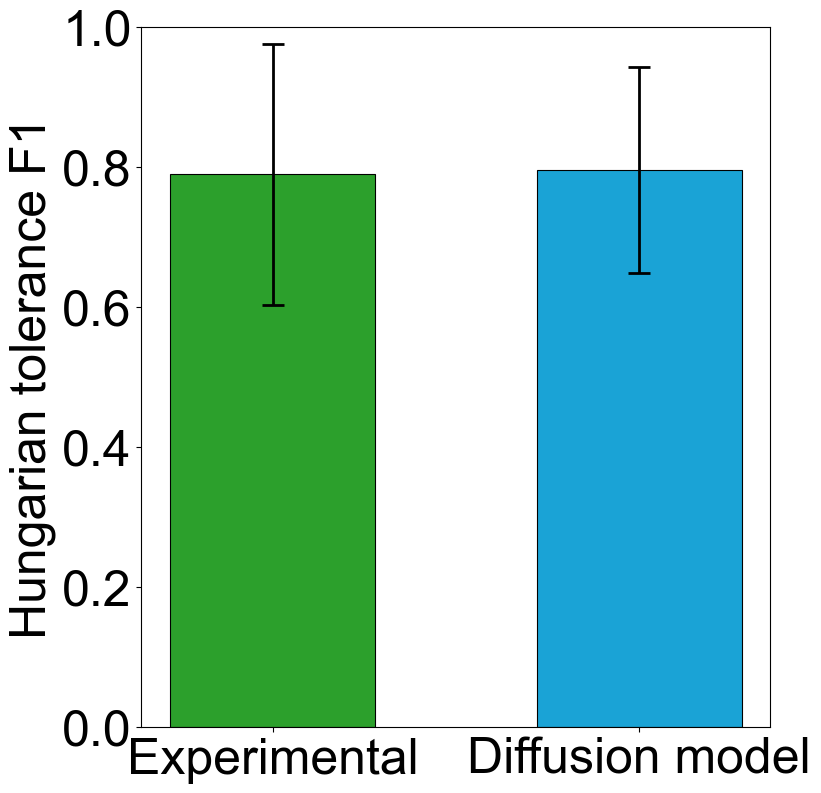

In [10]:
import matplotlib.font_manager as fm
from IPython.display import display

PLOT_FONT_PATH = Path('/hpc/group/youlab/ks723/miniconda3/Lingchong/fonts/ARIAL.TTF')
if not PLOT_FONT_PATH.is_file():
    raise FileNotFoundError(f'Arial font file not found: {PLOT_FONT_PATH}')
fm.fontManager.addfont(str(PLOT_FONT_PATH))
PLOT_FONT_FAMILY = fm.FontProperties(fname=str(PLOT_FONT_PATH)).get_name()
PLOT_FONT_SIZE = 36
PLOT_LABEL_FONTSIZE = 36
PLOT_TICK_FONTSIZE = 36
plt.rcParams.update({'font.family': PLOT_FONT_FAMILY, 'font.size': PLOT_FONT_SIZE})

domains = ['Real experimental', 'Synthetic diffusion']
colors = ['tab:green', '#1AA3D6']
overall = summary.loc[(summary['subset'] == 'all') & (summary['metric'] == 'tolerance_f1')]
means = [float(overall.loc[overall['domain'] == domain, 'mean'].iloc[0]) for domain in domains]
stds = [float(overall.loc[overall['domain'] == domain, 'std'].iloc[0]) for domain in domains]

fig, ax = plt.subplots(figsize=(8.5, 10))
x = np.arange(len(domains)) * 0.75
ax.bar(x, means, yerr=stds, capsize=8, width=0.42, color=colors,
       edgecolor='black', linewidth=0.8, error_kw={'elinewidth': 2.0, 'capthick': 2.0})
ax.set_xticks(x, ['Experimental', 'Diffusion model'])
ax.set_ylabel('Hungarian tolerance F1', fontsize=PLOT_LABEL_FONTSIZE,
              fontfamily=PLOT_FONT_FAMILY)
# ax.set_title('Experimental-NMAX decoder: mean ± SD\n(n=132)',
#              fontsize=PLOT_LABEL_FONTSIZE, fontfamily=PLOT_FONT_FAMILY)
ax.set_ylim(0, 1)
ax.tick_params(axis='both', labelsize=PLOT_TICK_FONTSIZE)
for tick_label in ax.get_xticklabels():
    tick_label.set_fontfamily(PLOT_FONT_FAMILY)
for tick_label in ax.get_yticklabels():
    tick_label.set_fontfamily(PLOT_FONT_FAMILY)
fig.subplots_adjust(bottom=0.14, left=0.24, right=0.98, top=0.84)
display(fig)


In [ ]:
from pathlib import Path as _ExportPath
import sys as _export_sys
_EXPORT_ROOT = next(p for p in (_ExportPath.cwd(), *_ExportPath.cwd().parents)
                    if (p / 'figure_exports').is_dir())
if str(_EXPORT_ROOT) not in _export_sys.path:
    _export_sys.path.insert(0, str(_EXPORT_ROOT))
import figure_exports as _figure_exports
# Vector PDF export: Supp. Fig. 24D — experimental-trained decoder on synthetic patterns
# Run immediately after the preceding plotting/analysis cell.
from pathlib import Path
import runpy as _vector_runpy

# Locate the project from the notebook working directory; no sys.path changes.
VECTOR_PROJECT_ROOT = next(
    _p for _p in (Path.cwd(), *Path.cwd().parents)
    if (_p / 'figure_exports').is_dir()
)
save_vector_pdf = vars(_figure_exports)['save_vector_pdf']
VECTOR_DIR = VECTOR_PROJECT_ROOT / 'information_encoding_decoding' / 'vector based plots'

save_vector_pdf(fig, VECTOR_DIR / 'SuppFig24D_real_to_synthetic.pdf')


In [13]:
from pathlib import Path as _DataPath
import sys as _data_sys
_DATA_ROOT = next(p for p in (_DataPath.cwd(), *_DataPath.cwd().parents) if (p / 'paper_paths.py').is_file())
if str(_DATA_ROOT) not in _data_sys.path: _data_sys.path.insert(0, str(_DATA_ROOT))
from paper_paths import figure_source_path as _figure_source_path
settings = {
    'task': 'experimental-NMAX inverse decoder evaluated on held-out synthetic diffusion images',
    'checkpoint': checkpoint_provenance,
    'device': str(device),
    'prediction_threshold': PREDICTION_THRESHOLD,
    'matching_algorithm': 'hungarian',
    'matching_tolerance_pixels': MATCHING_TOLERANCE,
    'reported_variation': 'standard deviation across per-image values',
    'real_test_inventory': real_inventory,
    'synthetic_test_inventory': {'random': 96, 'fixed': 36, 'total': 132},
    'synthetic_random_directory': str(SYNTHETIC_RANDOM_DIR.resolve()),
    'synthetic_fixed_directory': str(SYNTHETIC_FIXED_DIR.resolve()),
    'fixed_generation_sample_selected': FIXED_GENERATION_SAMPLE,
    'sim_to_exp_controlnet_checkpoint': str(SIM_TO_EXP_CONTROLNET_CHECKPOINT.resolve()),
    'overlap_audit': overlap_audit,
    'synthetic_input_preprocessing': 'read RGB and resize to 256x256; no extra experimental crop',
}
with (_figure_source_path(OUTPUT_DIR / 'evaluation_settings.json')).open('w') as handle:
    json.dump(settings, handle, indent=2)
print(f'Saved outputs to {OUTPUT_DIR.resolve()}')


Saved outputs to /hpc/dctrl/ks723/Physics_constrained_DL_pattern_prediction/information_encoding_decoding/experimental_nmax_real_to_synthetic_evaluation
